# Does Studying More Actually Help?
**Mozilla Firefox Club - AI/ML task** | Author: Pavit Wadhwa, 26BCE2551

**Question.** A school wants to tell students that *"more study time means better grades"*. Is that true, and what matters more?

**Data.** UCI Student Performance dataset. **I chose the MATH file** (`student-mat.csv`, 395 students) as my main file, because its grades are more spread out and it has more struggling students, so it is a tougher test of the claim. The Portuguese file is used later for comparison.

**Key columns.** `G3` = final grade (0-20), `G1`/`G2` = period 1 and 2 grades, `studytime` = weekly study time in 4 bands (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h), `failures` = number of past class failures, `absences` = days absent.

> Tip for Colab: run the next cell (uncomment the lines) to upload the two CSV files. On your own computer, keep them in a `data/` folder next to this notebook.

In [1]:
# Colab: pick student-mat.csv and student-por.csv when asked. Local computer: this cell is skipped.
try:
    from google.colab import files
    uploaded = files.upload()   # upload student-mat.csv and student-por.csv
except ImportError:
    print("Not running on Colab - reading the CSV files from the data/ folder instead.")


Saving student-mat.csv to student-mat (2).csv
Saving student-por.csv to student-por (2).csv


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (8, 5)
SEED = 42            # used for jitter so charts look the same every run
rng = np.random.default_rng(SEED)

# Small helper functions (only numpy/pandas, no sklearn/scipy)
def pearson(a, b):
    """Pearson correlation between two columns."""
    return float(np.corrcoef(np.asarray(a, dtype=float), np.asarray(b, dtype=float))[0, 1])

def spearman(a, b):
    """Spearman = Pearson on ranks. Better for ordinal data like studytime."""
    return pearson(pd.Series(a).rank(), pd.Series(b).rank())

def r_squared(X, y):
    """R-squared of a linear fit y ~ X (with intercept), using least squares."""
    y = np.asarray(y, dtype=float)
    X = np.column_stack([np.ones(len(y)), np.asarray(X, dtype=float)])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    resid = y - X @ beta
    return 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()

def find_file(name):
    """Look in data/ first, then in the current folder (works locally and on Colab)."""
    for path in (os.path.join("data", name), name):
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"Could not find {name}. Put it in a 'data' folder or next to this notebook.")

## 1. Load the data
The files use `;` (semicolon) as the separator, not a comma.

In [3]:
math = pd.read_csv(find_file("student-mat.csv"), sep=";")
por = pd.read_csv(find_file("student-por.csv"), sep=";")

df = math.copy()      # main analysis uses the MATH file
print("Math shape:", math.shape, "| Portuguese shape:", por.shape)
df.head()

Math shape: (395, 33) | Portuguese shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.dtypes.value_counts()

,count
object,17
int64,16


## 2. Cleaning (with a short decision after each step)

In [5]:
print("Missing values (total):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values (total): 0
Duplicate rows: 0


**Decision:** No missing values and no duplicate rows, so nothing needs to be filled or dropped.

In [6]:
checks = {
    "G1 within 0-20": df.G1.between(0, 20).all(),
    "G2 within 0-20": df.G2.between(0, 20).all(),
    "G3 within 0-20": df.G3.between(0, 20).all(),
    "studytime within 1-4": df.studytime.between(1, 4).all(),
    "failures within 0-3": df.failures.between(0, 3).all(),
    "absences >= 0": (df.absences >= 0).all(),
}
for name, ok in checks.items():
    print(f"{name:25s} -> {ok}")

G1 within 0-20            -> True
G2 within 0-20            -> True
G3 within 0-20            -> True
studytime within 1-4      -> True
failures within 0-3       -> True
absences >= 0             -> True


**Decision:** All values are inside their allowed ranges, so no values are invalid.

In [7]:
zero = df[df.G3 == 0]
rest = df[df.G3 > 0]
print(f"Students with G3 == 0: {len(zero)} of {len(df)} ({len(zero)/len(df):.1%})")
print(f"Average G2   -> G3==0 group: {zero.G2.mean():.2f} | everyone else: {rest.G2.mean():.2f}")
print(f"Average absences -> G3==0 group: {zero.absences.mean():.2f} | everyone else: {rest.absences.mean():.2f}")
print("Students with G3==0 whose G2 was also 0:", int((zero.G2 == 0).sum()))

Students with G3 == 0: 38 of 395 (9.6%)
Average G2   -> G3==0 group: 4.66 | everyone else: 11.36
Average absences -> G3==0 group: 0.00 | everyone else: 6.32
Students with G3==0 whose G2 was also 0: 13


**Decision:** There are 38 students with a final grade of 0. Their earlier grades were low (average G2 about 4.7 vs 11.4), and **all of them have exactly 0 absences**. This looks like students who dropped out or never sat the final exam (their absences were probably not recorded), so a 0 likely does *not* mean "zero knowledge". I **keep them in the main analysis** (removing real rows without proof would be a choice too), but I **repeat the key correlations without them** as a robustness check in Section 4.

In [8]:
print(df.absences.describe().round(2))
q1, q3 = df.absences.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"\nOutlier rule (Q3 + 1.5*IQR) = {upper:.1f} absences")
print("Students above it:", int((df.absences > upper).sum()), "| maximum absences:", df.absences.max())

count    395.00
mean       5.71
std        8.00
min        0.00
25%        0.00
50%        4.00
75%        8.00
max       75.00
Name: absences, dtype: float64

Outlier rule (Q3 + 1.5*IQR) = 20.0 absences
Students above it: 15 | maximum absences: 75


**Decision:** A few students have very high absences (the maximum is 75). Those could be real (long illness) so I **keep them** but remember they can influence correlations. Absences is only a secondary factor in this project.

In [9]:
# Readable labels for studytime (keep the numeric column too)
labels = {1: "<2h", 2: "2-5h", 3: "5-10h", 4: ">10h"}
label_order = ["<2h", "2-5h", "5-10h", ">10h"]
df["studytime_label"] = pd.Categorical(df.studytime.map(labels), categories=label_order, ordered=True)

# Yes/no columns -> 1/0 (kept ready for later use; not needed for the main charts)
yes_no_cols = ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]
for col in yes_no_cols:
    df[col + "_num"] = (df[col] == "yes").astype(int)

df[["studytime", "studytime_label", "failures", "absences", "G1", "G2", "G3"]].head()

,studytime,studytime_label,failures,absences,G1,G2,G3
0,2,2-5h,0,6,5,6,6
1,2,2-5h,0,4,5,5,6
2,2,2-5h,3,10,7,8,10
3,3,5-10h,0,2,15,14,15
4,2,2-5h,0,4,6,10,10


**Decision:** `studytime` is an *ordered category* (not exact hours), so I add readable labels while keeping the numeric 1-4 column for correlations. The yes/no columns are converted to 1/0 but are not needed for the main question.

## 3. Study time vs final grade (G3)

In [10]:
summary = df.groupby("studytime_label", observed=True)["G3"].agg(["count", "mean", "median"]).round(2)
summary.columns = ["students (n)", "mean G3", "median G3"]
display(summary)

r_p = pearson(df.studytime, df.G3)
r_s = spearman(df.studytime, df.G3)
print(f"Pearson r  (studytime, G3) = {r_p:.3f}")
print(f"Spearman r (studytime, G3) = {r_s:.3f}")

# Robustness: same correlation without the G3 == 0 students
nz = df[df.G3 > 0]
print(f"Pearson r without G3==0 students = {pearson(nz.studytime, nz.G3):.3f}")

,students (n),mean G3,median G3
studytime_label,,,
<2h,105,10.05,10.0
2-5h,198,10.17,11.0
5-10h,65,11.40,12.0
>10h,27,11.26,12.0


Pearson r  (studytime, G3) = 0.098
Spearman r (studytime, G3) = 0.105
Pearson r without G3==0 students = 0.127


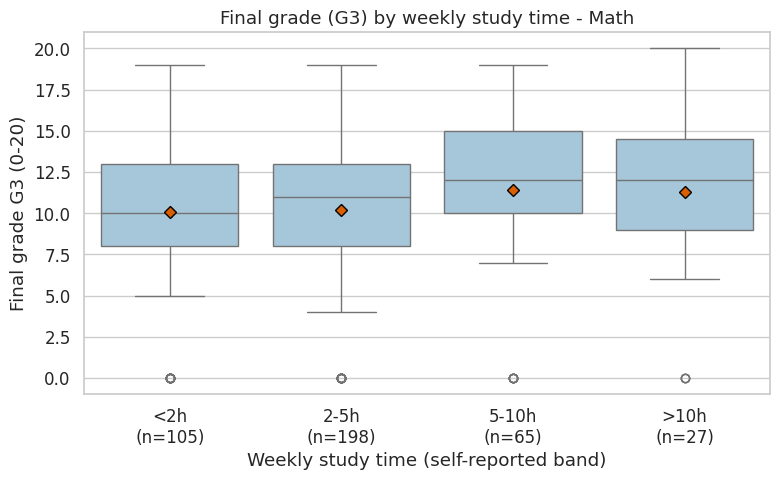

In [11]:
# CHART 1: G3 by study-time group
counts = df.studytime_label.value_counts().reindex(label_order)
fig, ax = plt.subplots()
sns.boxplot(data=df, x="studytime_label", y="G3", order=label_order, color="#9ecae1",
            showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "#d95f02", "markeredgecolor": "black"}, ax=ax)
ax.set_xticks(range(4))
ax.set_xticklabels([f"{l}\n(n={counts[l]})" for l in label_order])
ax.set_title("Final grade (G3) by weekly study time - Math")
ax.set_xlabel("Weekly study time (self-reported band)")
ax.set_ylabel("Final grade G3 (0-20)")
plt.tight_layout()
plt.show()

**Chart 1 interpretation.** Average final grade rises only a little with study time: about 10.1 and 10.2 for the two lowest bands, and about 11.3-11.4 for students studying more than 5 hours. The boxes overlap heavily, so many low-study students score higher than many high-study students. The overall link is weak (Pearson r = 0.10, Spearman r = 0.11), and the top group has only 27 students, so its average is not very reliable.

## 4. Two other factors: past failures and the previous grade (G2)
I compare how strongly each is related to G3 next to study time. Absences and G1 are shown too for context.

In [12]:
factors = ["studytime", "failures", "absences", "G1", "G2"]
corr_table = pd.DataFrame({
    "Pearson r with G3": [pearson(df[f], df.G3) for f in factors],
    "Spearman r with G3": [spearman(df[f], df.G3) for f in factors],
    "Pearson r (G3>0 only)": [pearson(nz[f], nz.G3) for f in factors],
}, index=factors).round(3)
display(corr_table)

,Pearson r with G3,Spearman r with G3,Pearson r (G3>0 only)
studytime,0.098,0.105,0.127
failures,-0.360,-0.361,-0.294
absences,0.034,0.018,-0.213
G1,0.801,0.878,0.892
G2,0.905,0.957,0.966


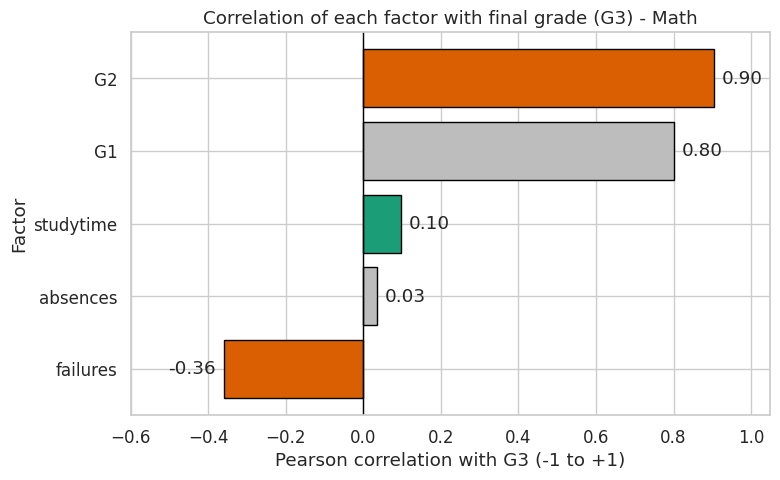

In [13]:
# CHART 2: how strongly each factor relates to G3
plot_data = pd.Series({f: pearson(df[f], df.G3) for f in factors}).sort_values()   # unrounded values
colors = []
for f in plot_data.index:
    if f == "studytime":
        colors.append("#1b9e77")        # green: the school's claim
    elif f in ("failures", "G2"):
        colors.append("#d95f02")        # orange: my 2 chosen factors
    else:
        colors.append("#bdbdbd")        # grey: extra context

fig, ax = plt.subplots()
ax.barh(plot_data.index, plot_data.values, color=colors, edgecolor="black")
ax.axvline(0, color="black", linewidth=1)
for i, v in enumerate(plot_data.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right")
ax.set_xlim(-0.6, 1.05)
ax.set_title("Correlation of each factor with final grade (G3) - Math")
ax.set_xlabel("Pearson correlation with G3 (-1 to +1)")
ax.set_ylabel("Factor")
plt.tight_layout()
plt.show()

**Chart 2 interpretation.** The previous-period grade G2 is by far the strongest factor (r = 0.90), then failures pull grades down (r = -0.36), while study time (r = 0.10) is weak. Absences look almost unrelated (r = 0.03), but that is misleading: all 38 students with G3 = 0 have 0 absences recorded, and without them absences become negatively related (r = -0.21). Correlation does not prove cause, so these show *what goes with* high grades, not what produces them.

## 5. Brownie points
### 5a. Math vs Portuguese

In [14]:
def compare_row(data, name):
    nz_ = data[data.G3 > 0]
    return {
        "subject": name,
        "students": len(data),
        "mean G3": data.G3.mean(),
        "r(studytime, G3)": pearson(data.studytime, data.G3),
        "r(failures, G3)": pearson(data.failures, data.G3),
        "r(absences, G3)": pearson(data.absences, data.G3),
        "r(G2, G3)": pearson(data.G2, data.G3),
        "r(studytime, G3) no zeros": pearson(nz_.studytime, nz_.G3),
    }

compare = pd.DataFrame([compare_row(math, "Math"), compare_row(por, "Portuguese")]).set_index("subject").round(3)
display(compare)

print("\nMean G3 by study-time band:")
display(pd.DataFrame({
    "Math": math.groupby("studytime").G3.mean(),
    "Portuguese": por.groupby("studytime").G3.mean(),
}).round(2))

,students,mean G3,"r(studytime, G3)","r(failures, G3)","r(absences, G3)","r(G2, G3)","r(studytime, G3) no zeros"
subject,,,,,,,
Math,395,10.415,0.098,-0.360,0.034,0.905,0.127
Portuguese,649,11.906,0.250,-0.393,-0.091,0.919,0.246



Mean G3 by study-time band:


,Math,Portuguese
studytime,,
1,10.05,10.84
2,10.17,12.09
3,11.40,13.23
4,11.26,13.06


**Takeaway:** The story is the same in both subjects: G2 is the strongest factor, failures are clearly negative, and study time is positive but weaker. Study time matters somewhat more in Portuguese (r about 0.25) than in Math (r about 0.10).

### 5b. How much do earlier grades explain the final grade?

,R-squared
G3 ~ studytime,0.010
G3 ~ failures,0.130
G3 ~ G1,0.642
G3 ~ G2,0.819
G3 ~ G1 + G2,0.822


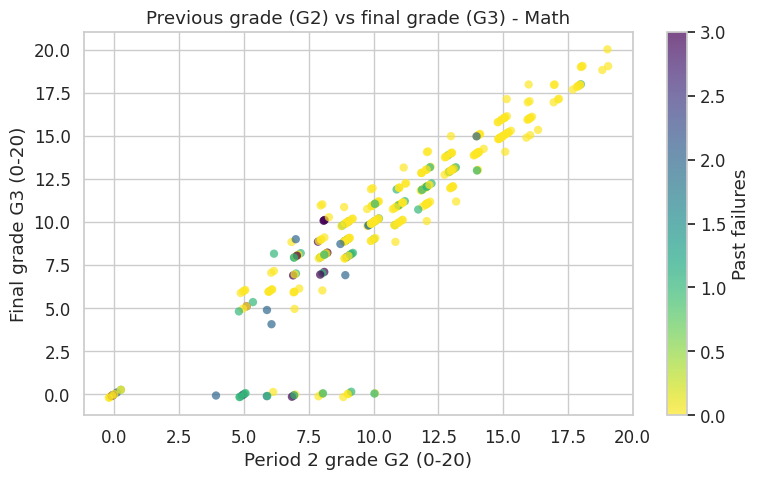

In [15]:
y = df.G3.to_numpy(dtype=float)
r2_table = pd.Series({
    "G3 ~ studytime": r_squared(df[["studytime"]], y),
    "G3 ~ failures": r_squared(df[["failures"]], y),
    "G3 ~ G1": r_squared(df[["G1"]], y),
    "G3 ~ G2": r_squared(df[["G2"]], y),
    "G3 ~ G1 + G2": r_squared(df[["G1", "G2"]], y),
}, name="R-squared").round(3)
display(r2_table.to_frame())

# Bonus chart: G2 vs G3 (small jitter so overlapping points are visible)
fig, ax = plt.subplots()
jitter = rng.normal(0, 0.12, len(df))
scatter = ax.scatter(df.G2 + jitter, df.G3 + jitter, c=df.failures, cmap="viridis_r", alpha=0.7, edgecolor="none")
ax.set_title("Previous grade (G2) vs final grade (G3) - Math")
ax.set_xlabel("Period 2 grade G2 (0-20)")
ax.set_ylabel("Final grade G3 (0-20)")
fig.colorbar(scatter, ax=ax, label="Past failures")
plt.tight_layout()
plt.show()

**Takeaway:** G2 alone explains about 82% of the variation in G3, G1 + G2 together about 82%, but study time explains only about 1%. G2 is so strong partly because it measures the *same* skill earlier in the same year, so it does not tell us what to change. The dots that sit at G3 = 0 while G2 is above 0 are the students who likely skipped the final exam.

### 5c. Group comparison (school and home address)

In [16]:
def group_table(col):
    rows = []
    for g, sub in df.groupby(col):
        rows.append({col: g, "n": len(sub), "mean G3": sub.G3.mean(),
                     "mean studytime": sub.studytime.mean(),
                     "r(studytime, G3)": pearson(sub.studytime, sub.G3)})
    return pd.DataFrame(rows).set_index(col).round(2)

print("By school (GP vs MS):")
display(group_table("school"))
print("By address (U = urban, R = rural):")
display(group_table("address"))

By school (GP vs MS):


,n,mean G3,mean studytime,"r(studytime, G3)"
school,,,,
GP,349,10.49,2.06,0.07
MS,46,9.85,1.83,0.35


By address (U = urban, R = rural):


,n,mean G3,mean studytime,"r(studytime, G3)"
address,,,,
R,88,9.51,2.07,0.20
U,307,10.67,2.03,0.07


**Takeaway:** Rural students and the MS school score a bit lower on average. The study-time link looks stronger in the small MS group (r about 0.35, n = 46) and for rural students (r about 0.20) than in GP or urban students (r about 0.07), but these groups are small, so I treat the differences as hints, not conclusions.

### 5d. A simple regression line (G3 ~ studytime) and its limits

G3 = 9.33 + 0.53 * studytime  (R-squared = 0.010)


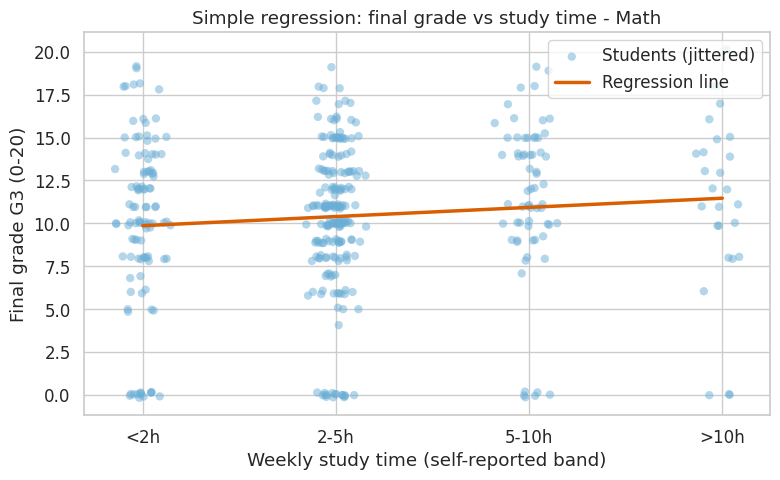

In [17]:
slope, intercept = np.polyfit(df.studytime, df.G3, 1)
r2_line = r_squared(df[["studytime"]], df.G3)
print(f"G3 = {intercept:.2f} + {slope:.2f} * studytime  (R-squared = {r2_line:.3f})")

fig, ax = plt.subplots()
ax.scatter(df.studytime + rng.normal(0, 0.06, len(df)), df.G3 + rng.normal(0, 0.1, len(df)),
           alpha=0.5, color="#6baed6", edgecolor="none", label="Students (jittered)")
xs = np.array([1, 4])
ax.plot(xs, intercept + slope * xs, color="#d95f02", linewidth=2.5, label="Regression line")
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(label_order)
ax.set_title("Simple regression: final grade vs study time - Math")
ax.set_xlabel("Weekly study time (self-reported band)")
ax.set_ylabel("Final grade G3 (0-20)")
ax.legend()
plt.tight_layout()
plt.show()

**What the line says:** moving up one study-time band goes with about +0.5 marks on average.

**Limits of this line:**
- **Low R-squared (about 0.01):** the line explains almost none of the differences between students.
- **Coarse input:** study time is just 4 self-reported bands, not measured hours, and the line assumes equal steps between bands.
- **Correlation is not causation:** motivated or stronger students may study more (or report more).
- **Outliers pull the line:** the 38 students with G3 = 0 sit far below everyone else.
- **Narrow data:** two schools in Portugal, one period, so it may not apply elsewhere.

## 6. Findings summary (numbers computed from the data above)

In [18]:
g = df.groupby("studytime").G3.mean()
print("FINDINGS (Math file)")
print(f"1. Study time vs G3: Pearson r = {r_p:.2f}, Spearman r = {r_s:.2f}; R-squared = {r2_line:.3f} (explains ~{r2_line:.0%} of grade differences).")
print(f"2. Average G3 goes from {g.loc[1]:.1f} (<2h) to {g.loc[3]:.1f} (5-10h) and {g.loc[4]:.1f} (>10h): a small, uneven rise.")
print(f"3. Past failures: r = {pearson(df.failures, df.G3):.2f} -> students with earlier failures do clearly worse.")
print(f"4. Previous grade G2: r = {pearson(df.G2, df.G3):.2f}; G2 alone explains {r_squared(df[['G2']], y):.0%} of G3.")
print(f"5. Robustness: without the {len(zero)} students with G3=0, study time r = {pearson(nz.studytime, nz.G3):.2f}, failures r = {pearson(nz.failures, nz.G3):.2f}, G2 r = {pearson(nz.G2, nz.G3):.2f}.")
print(f"6. Portuguese file: study time r = {pearson(por.studytime, por.G3):.2f}, failures r = {pearson(por.failures, por.G3):.2f}, G2 r = {pearson(por.G2, por.G3):.2f} (same pattern).")

FINDINGS (Math file)
1. Study time vs G3: Pearson r = 0.10, Spearman r = 0.11; R-squared = 0.010 (explains ~1% of grade differences).
2. Average G3 goes from 10.0 (<2h) to 11.4 (5-10h) and 11.3 (>10h): a small, uneven rise.
3. Past failures: r = -0.36 -> students with earlier failures do clearly worse.
4. Previous grade G2: r = 0.90; G2 alone explains 82% of G3.
5. Robustness: without the 38 students with G3=0, study time r = 0.13, failures r = -0.29, G2 r = 0.97.
6. Portuguese file: study time r = 0.25, failures r = -0.39, G2 r = 0.92 (same pattern).


**Conclusion.** Studying more goes with slightly better grades, but it is a weak factor. Earlier performance (G2) and past failures matter far more. I do not claim that study time *causes* better grades (see `memo.md`).

---
*Final step: click **Kernel -> Restart & Run All** (Colab: **Runtime -> Restart and run all**) and make sure every cell runs without errors, then save the notebook with outputs visible before uploading to GitHub.*